# Week 3 - FromAtomic Trajectories to Diffusion

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pylab as p
import  seaborn as sns
import pandas as pd

from sympy.physics.mechanics import potential_energy
from sympy.physics.units import velocity

In [3]:
def initialize_lattice(n_particles,box_length):
    n_side = int(np.ceil(np.sqrt(n_particles)))
    space = box_length / n_side

    corr = np.arange(n_side) * space + .5 * space

    position = np.array([(x,y) for x in corr for y in corr])
    return position[:n_particles]


In [4]:
box = initialize_lattice(9,12)
box

array([[ 2.,  2.],
       [ 2.,  6.],
       [ 2., 10.],
       [ 6.,  2.],
       [ 6.,  6.],
       [ 6., 10.],
       [10.,  2.],
       [10.,  6.],
       [10., 10.]])

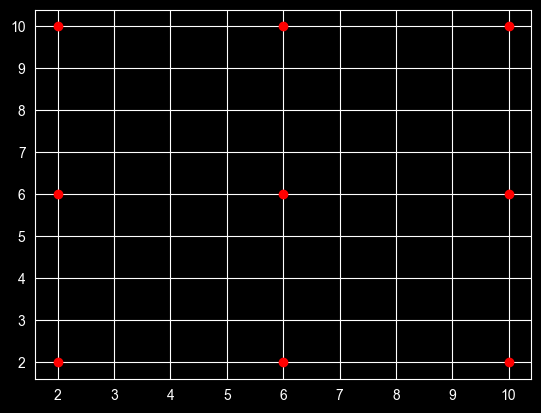

In [5]:
plt.scatter(box[:,0],box[:,1],color='red')

This function sets up the starting locations of $N$ particles in a 2D simulation box by arranging them on a structured grid (a square lattice) rather than placing them randomly.

### The Purpose of Lattice Initialization

If you place particles randomly in a liquid or dense fluid simulation, two particles will inevitably end up extremely close to each other. Because of the steep $r^{-12}$ repulsive term in the Lennard-Jones potential $U(r)$, random placement produces near-infinite initial forces that immediately crash the integration algorithm.

Placing particles on an evenly spaced lattice guarantees a safe minimum distance between all atoms before the simulation begins.

---

### Step-by-Step Code Breakdown

#### 1. Determining Grid Dimensions (`n_side`)

```python
n_side = int(np.ceil(np.sqrt(n_particles)))

```

* To arrange $N$ total particles in a 2D square grid, you need a grid with $n_{\text{side}}$ points along each axis.
* `np.sqrt(n_particles)` calculates the required side length of the grid.
* `np.ceil(...)` rounds up to the nearest integer so the grid has enough total slots ($n_{\text{side}}^2 \ge N$).
* *Example:* If `n_particles = 10`, $\sqrt{10} \approx 3.16$. Rounding up gives `n_side = 4`, creating a $4 \times 4 = 16$ slot grid.



#### 2. Calculating Grid Spacing (`spacing`)

```python
spacing = box_length / n_side

```

* Divides the length of the simulation box (`box_length`) by the number of grid points along one axis (`n_side`) to determine the uniform distance between adjacent grid sites.

#### 3. Defining 1D Grid Coordinates (`coords`)

```python
coords = np.arange(n_side) * spacing + 0.5 * spacing

```

* `np.arange(n_side)` creates integer indices: `[0, 1, 2, ..., n_side - 1]`.
* Multiplying by `spacing` scales these indices to physical box lengths: `[0, spacing, 2*spacing, ...]`.
* Adding `0.5 * spacing` offsets the entire grid into the center of each grid cell, keeping particles away from the outer box boundaries.

#### 4. Generating 2D Position Pairs (`positions`)

```python
positions = np.array([(x, y) for x in coords for y in coords], dtype=float)

```

* Uses a double loop (Cartesian product) to combine 1D $x$ and $y$ coordinates into 2D $(x, y)$ coordinate pairs for all $n_{\text{side}}^2$ slots on the grid.

#### 5. Truncating to the Exact Particle Count

```python
return positions[:n_particles]

```

* Because $n_{\text{side}}^2$ may be greater than `n_particles`, slicing `[:n_particles]` takes only the first $N$ generated positions and discards the unused extra grid slots.
Here is the explanation simplified even further, broken down into two main questions:

---

### 1. What is the overall goal (object) of this function?

The main goal is to **prevent particles from exploding at step zero**.

If you throw 10 particles into a box completely at random, two of them will almost certainly land on top of each other. Because of the steep $r^{-12}$ Lennard-Jones potential wall, near-zero distance creates **near-infinite repulsive force**. The very first timestep would blow up your simulation.

Placing particles on an evenly spaced grid guarantees every particle starts at a safe, comfortable distance from its neighbors.

---

### 2. Why is `n_side` calculated with `np.ceil(np.sqrt(...))`?

Think of organizing $N$ eggs into a square egg carton:

* If you have **9 particles**, you need a $3 \times 3$ grid ($\sqrt{9} = 3$).
* What if you have **10 particles**? A $3 \times 3$ grid only holds 9 items. You don't have enough room!
* $\sqrt{10} \approx 3.16$. You can't have $3.16$ slots along a row, so `np.ceil()` **rounds up** $3.16$ to **$4$**.
* A $4 \times 4$ grid gives you **16 total slots**, which is more than enough to fit all 10 particles.

---

### 3. Why add `+ 0.5 * spacing`?

Without `+ 0.5 * spacing`, the grid points along a 10-meter box with 2-meter spacing would be placed at:

$$\text{Positions: } [0, 2, 4, 6, 8]$$

Notice that the first particle is sitting **exactly on the left wall** ($x = 0$).

By adding `0.5 * spacing` (which is $1$ meter in this example), all positions shift right into the **centers of the grid cells**:

$$\text{Positions: } [1, 3, 5, 7, 9]$$

This keeps particles centered in their designated areas and away from the outer edges of the simulation box.

****
In this function, **`box_length`** represents the total width (and height) of your 2D square simulation box:

$$\text{Simulation Area} = \text{box\_length} \times \text{box\_length}$$

Here is how `box_length` dictates the spatial arrangement in this code:

---

### 1. It Sets the Boundaries ($0$ to `box_length`)

The simulation box spans from coordinate $0$ to `box_length` along both the $x$ and $y$ axes:

* $x \in [0, \text{box\_length}]$
* $y \in [0, \text{box\_length}]$

---

### 2. It Determines Grid Cell Size (`spacing`)

The code divides the entire box length into $n_{\text{side}}$ equal segments:

$$\text{spacing} = \frac{\text{box\_length}}{n_{\text{side}}}$$

* **Larger `box_length`:** Increases `spacing`, pushing particles further apart (lower density / gas-like state).
* **Smaller `box_length`:** Decreases `spacing`, placing particles closer together (higher density / liquid-like state).

---

### 3. Concrete Example

If `box_length = 10.0` and `n_particles = 9`:

1. $n_{\text{side}} = \lceil\sqrt{9}\rceil = 3$ grid points per side.
2. $\text{spacing} = \frac{10.0}{3} = 3.33$ distance units per cell slot.
3. `coords` will be calculated as:

$$\text{coords} = [0, 3.33, 6.66] + 0.5 \times 3.33 = [1.67, 5.00, 8.33]$$



All particles are now placed inside the $10.0 \times 10.0$ box bounds, perfectly centered within their $3.33$-wide sub-cells:

```
(0, 10) ┌─────────────────────────┐ (10, 10)
        │   •       •       •     │
        │ (1.67,8.33)(5.00,8.33)(8.33,8.33)
        │                         │
        │   •       •       •     │
        │ (1.67,5.00)(5.00,5.00)(8.33,5.00)
        │                         │
        │   •       •       •     │
        │ (1.67,1.67)(5.00,1.67)(8.33,1.67)
(0, 0)  └─────────────────────────┘ (10, 0)

```

In [6]:
box

array([[ 2.,  2.],
       [ 2.,  6.],
       [ 2., 10.],
       [ 6.,  2.],
       [ 6.,  6.],
       [ 6., 10.],
       [10.,  2.],
       [10.,  6.],
       [10., 10.]])

In [7]:
import numpy as np

box_length = 10.0
positions_wrapped = np.array([
    [0.2, 5.0],
    [9.8, 5.0]
])

In [8]:
positions_wrapped

array([[0.2, 5. ],
       [9.8, 5. ]])

In [9]:
def lj_forces_abd_energy(positions_wrapped,box_length):
    r = positions_wrapped

    #displacement
    dr = r[:,None,:] - r[None,:,:]
    #return dr

    #minimum_image convention
    dr = dr - box_length*np.rint(dr/box_length)
    #return dr
    r2 = np.sum(dr**2,axis=2)
    #return r2
    np.fill_diagonal(r2,np.inf)
    #return r2

    inv_r2 = 1/r2
    inv_r6 = inv_r2 ** 3
    #return inv_r2,inv_r6

    #F_ij = 24 [2 r^-14 - r^-8] r_ij
    prefactor = 24 * inv_r2 *(2 *inv_r6**2 - inv_r6)
    #return prefactor
    prefactor[np.isinf(r2)] = 0.0
    forces = np.sum(prefactor[:,:,None] * dr,axis=1)
    #return forces

    # Pair potential; factor 1/2 removes double counting
    pair_u = 4 * (inv_r6**2 - inv_r6)
    np.fill_diagonal(pair_u,0)
    potential_energy = .5 * np.sum(pair_u)

    return forces, potential_energy


In [32]:
#distance = lj_forces_abd_energy(positions_wrapped,box_length)
#print(distance)
#distance.shape

[[[ 0.   0. ]
  [-9.6  0. ]]

 [[ 9.6  0. ]
  [ 0.   0. ]]]


(2, 2, 2)

In [30]:
#distance = lj_forces_abd_energy(positions_wrapped,box_length)
#print(distance)
#distance.shape

[[[ 0.   0. ]
  [ 0.4  0. ]]

 [[-0.4  0. ]
  [ 0.   0. ]]]


(2, 2, 2)

In [45]:
#r2 = lj_forces_abd_energy(positions_wrapped,box_length)
#print(r2)
#print(r2.shape)

[[0.   0.16]
 [0.16 0.  ]]
(2, 2)


In [48]:
#r2 = lj_forces_abd_energy(positions_wrapped,box_length)
#print(r2)
#print(r2.shape)

[[ inf 0.16]
 [0.16  inf]]
(2, 2)


In [51]:
#r2,r6 = lj_forces_abd_energy(positions_wrapped,box_length)
#print(r2)
#print(r6)

[[0.   6.25]
 [6.25 0.  ]]
[[  0.       244.140625]
 [244.140625   0.      ]]


In [54]:
#prefac = lj_forces_abd_energy(positions_wrapped,box_length)
#print(prefac)


[[       0.         17844772.33886808]
 [17844772.33886808        0.        ]]


In [56]:
forces = lj_forces_abd_energy(positions_wrapped,box_length)
print(forces)

[[ 7137908.93554721        0.        ]
 [-7137908.93554721        0.        ]]


In [10]:
forces,potential_energy = lj_forces_abd_energy(positions_wrapped, box_length)
print(forces,potential_energy)

[[ 7137908.93554721        0.        ]
 [-7137908.93554721        0.        ]] 237442.01660157263


# Mastering the Lennard–Jones force and energy function

Let's study this as a computational scientist, not just as someone learning Python. By the end, you should understand the physical model, the mathematics, the numerical implementation, how this function fits into molecular dynamics, and how to verify that your simulation is correct.

Your function calculates two things:

1. The force acting on every particle due to every other particle.
2. The total potential energy of the system.

These are the physical quantities that allow a molecular dynamics simulation to move particles through time.

## 1. The big picture: what is this code actually doing?

Imagine a box containing 36 particles. Each particle represents an atom or molecule in a simplified model. The particles interact with one another, so they attract or repel each other depending on their separation.

[モノのコトワリ](https://images.openai.com/static-rsc-4/QiaLuRyQD959UjlMkbE8gBBAHEW57Orh4NCO5uwEKTrQtZuXHaMsa4PgxOzd1KpxedOUn9sGxNiEDMY4IivtJMdufdGqpXl8sD1Xxvbb-BXWFh-MLIgmCLYpqzeAmVwwJ4kWEgiLWyyctOHtG29zvuB4o1FGHf7hhLOi3whOMxM?purpose=inline)

[Bonding in Solids | Physical  Metallurgy](https://images.openai.com/static-rsc-4/Is_VaI3sc8djub8PBfLJUS-HgqeUGkhTSvuRhi9XJGXMGyw7QKxWhh9xd-L1GZioc3X6swnwGDfhpBMmTaz3rEIIyv1PIpp_3menMxtqhhCi7T8lTx7V8_JrcqFF0MswJz2UFpy9mgPWKdAgAslnmuVurNvYzf8kfKPmPEoLNJQ?purpose=inline)

[Achievements and Prospects of Molecular Dynamics Simulations in Thermofluid Sciences | MDPI](https://images.openai.com/static-rsc-4/5XUUiV_MM16f7UphcfmouFqtJbIGay8IB3WBaZgqTjr-n8lXhfQldyrYcw53ZOg0C5VU4_E5HQPGiq8XOGPZW4LMrBZQPwmFGPKnbXgSPRSeaxD3-SikBfejhpd0o_fJGTp-PHCNBHuuBb3YzqvEa84UW72uL-8HRT173QBfnhE?purpose=inline)

7

At every MD time step, the simulation needs to answer three questions:

- Where are all the particles?
- What forces do they exert on one another at these positions?
- Given these forces, how should the particles move next?

Your function answers the second question. The MD integrator, such as Position Verlet, uses its output to answer the third.

Particle positions \\(\mathbf r_1,\mathbf r_2,\ldots,\mathbf r_N\\)

Calculate pairwise separations \\(r\_{ij}\\)

Lennard–Jones interaction model \\(U(r\_{ij})\\)

Forces

\\(\mathbf F_i=-\nabla_i U\\)

Potential energy

\\(U\_{\mathrm{total}}\\)

MD integrator updates the positions

This cycle repeats thousands, millions, or even billions of times in a real simulation.

One important distinction: Lennard–Jones is the interaction model, not the MD algorithm. The model tells us how particles interact; the integration algorithm tells us how to advance their motion.

## 2. The physics: why do particles interact this way?

### 2.1 The Lennard–Jones potential

The Lennard–Jones (LJ) potential is a simplified model for interactions between neutral, nonbonded particles. It is commonly used to model van der Waals-like attraction and short-range repulsion.

Its standard form is

\\[ \boxed{ U(r)=4\epsilon\left[ \left(\frac{\sigma}{r}\right)^{12} -\left(\frac{\sigma}{r}\right)^6 \right] } \\]

Here:

- \\(r\\): distance between two particles.
- \\(\epsilon\\): depth of the attractive energy well.
- \\(\sigma\\): distance at which the potential energy equals zero.
- \\(U(r)\\): interaction potential energy of that particle pair.

The potential has two competing contributions:

\\[ U(r)= \underbrace{4\epsilon\left(\frac{\sigma}{r}\right)^{12}}\_{\text{repulsion}} - \underbrace{4\epsilon\left(\frac{\sigma}{r}\right)^6}\_{\text{attraction}} \\]

[モノのコトワリ](https://images.openai.com/static-rsc-4/QiaLuRyQD959UjlMkbE8gBBAHEW57Orh4NCO5uwEKTrQtZuXHaMsa4PgxOzd1KpxedOUn9sGxNiEDMY4IivtJMdufdGqpXl8sD1Xxvbb-BXWFh-MLIgmCLYpqzeAmVwwJ4kWEgiLWyyctOHtG29zvuB4o1FGHf7hhLOi3whOMxM?purpose=inline)

Repulsion: the \\(r^{-12}\\) term

When particles get extremely close, the energy increases sharply. In real atoms, the steep repulsion is associated mainly with overlapping electron clouds and the Pauli exclusion principle. The \\(r^{-12}\\) form is a convenient approximation, not a fundamental law.

[Lennard-Jones potential @ Chemistry Dictionary & Glossary](https://images.openai.com/static-rsc-4/oKy2hp4CI9ET5FyuYLXfZ9auPzU5qbwaaqwp9cvcAVFTIpTP93dlmZc0FbkuDArZCaGEa_gufoeOQkwVX8kd0n2TKY5oKCmEPP0Kgn-wdCY1Cr33Rx4J76hcjVaKC6dT2uhiniROQSrNwXiTpB5bv8crTthj4PiHOAwD57EK1C0?purpose=inline)

Attraction: the \\(r^{-6}\\) term

At intermediate distances, the potential is negative. This represents attraction, commonly associated with London dispersion interactions in the LJ model.

### 2.2 What happens at different distances?

| Distance              | Potential energy           | Physical interpretation                   |
| --------------------- | -------------------------- | ----------------------------------------- |
| \\(r\ll\sigma\\)      | Very large and positive    | Strong repulsion                          |
| \\(r=\sigma\\)        | Zero                       | Attraction and repulsion cancel in energy |
| \\(r=2^{1/6}\sigma\\) | Minimum, \\(-\epsilon\\)   | Most favorable pair separation            |
| \\(r\gg\sigma\\)      | Approaches zero from below | Weak attraction                           |

Notice that \\(r=\sigma\\) is not the equilibrium separation. The minimum is at

\\[ r\_{\min}=2^{1/6}\sigma\approx1.12246\sigma \\]

At this distance, the force between the pair is zero. If the particles move closer, they repel; if they move farther apart, they attract.

That last statement is about the radial force. The vector force still points along the line connecting the two particles.

### 2.3 Why your code uses reduced units

Your code uses

\\[ \epsilon=1,\qquad \sigma=1,\qquad m=1 \\]

These are reduced units. Rather than expressing every quantity in joules, meters, and kilograms, you measure energy, distance, and mass relative to chosen reference values.

The corresponding time unit is

\\[ \tau=\sigma\sqrt{\frac{m}{\epsilon}} \\]

So the simulation's time, temperature, energy, and distance are dimensionless quantities expressed in LJ units.

This makes the model easier to study, but it also means you should not interpret its numerical values as real physical values for water, proteins, or a specific material unless you have chosen and justified appropriate parameters.

## 3. Derive the force equation before touching the code

This is the most important mathematical part of the function.

### 3.1 From potential energy to force

For two particles, their interaction energy depends on the distance between them:

\\[ U(r)=4\left(r^{-12}-r^{-6}\right) \\]

We have set \\(\epsilon=\sigma=1\\).

The force is the negative derivative of potential energy with respect to position. Because this potential depends only on distance, we can first calculate the radial force:

\\[ F_r=-\frac{dU}{dr} \\]

Differentiate each term:

\\[ \frac{dU}{dr} =4\left(-12r^{-13}+6r^{-7}\right) \\]

Therefore,

\\[ F_r=48r^{-13}-24r^{-7} \\]

Factor out \\(24r^{-1}\\):

\\[ F_r=24\left(2r^{-14}-r^{-8}\right) \\]

This is the radial force magnitude with a signed direction: it is positive for repulsion and negative for attraction under the outward radial convention.

But MD needs a vector force, not just a scalar. Define

\\[ \mathbf r\_{ij}=\mathbf r_i-\mathbf r_j, \qquad r\_{ij}=\lVert\mathbf r\_{ij}\rVert \\]

The vector force on particle \\(i\\) due to particle \\(j\\) is

\\[ \boxed{ \mathbf F\_{ij} =24\left(2r\_{ij}^{-14}-r\_{ij}^{-8}\right) \mathbf r\_{ij} } \\]

This is exactly the mathematical expression in your code comment.

Notice the distinction: the scalar radial force is multiplied by the displacement vector, which supplies the direction and the vector magnitude factor.

### 3.2 Why the force matters in MD

Newton's second law says

\\[ m_i\mathbf a_i=\mathbf F_i \\]

The total force on particle \\(i\\) is the sum of the forces from all other particles:

\\[ \boxed{ \mathbf F_i=\sum\_{j\ne i}\mathbf F\_{ij} } \\]

Your function calculates this sum for every particle. The resulting force array is passed to the MD integrator, which uses it to update particle positions.

This is the standard relationship between a pair potential and the forces used in molecular dynamics.&#x20;

[image](https://www.google.com/s2/favicons?domain=https://www.lptmc.jussieu.fr\&sz=32)

lptmc.jussieu.fr+1



## 4. Now understand every line of the code

### Part A — The function and input

```
def lj_forces_and_energy(positions_wrapped, box_length):    """Return Lennard-Jones forces and potential energy in reduced units."""    r = positions_wrapped
```

The function receives two inputs:

- `positions_wrapped`: coordinates of all particles, kept inside the simulation box.
- `box_length`: length \\(L\\) of the square periodic box.

For \\(N\\) particles in 2D, the positions array has shape

\\[ (N,2) \\]

For example, with three particles:

```
r = np.array([    [1.0, 1.0],  # particle 0    [2.0, 1.0],  # particle 1    [1.0, 3.0]   # particle 2])
```

The variable `r` is simply a shorter name for the input. It does not make a separate copy.

Our goal is to calculate the force vector for each particle and one scalar total potential energy.

### Part B — Calculate every pair's displacement

```
dr = r[:, None, :] - r[None, :, :]
```

This line can look mysterious at first. Let's unpack it.

The displacement from particle \\(j\\) to particle \\(i\\) is

\\[ \mathbf r\_{ij}=\mathbf r_i-\mathbf r_j \\]

We need this for every pair, not just one pair.

Suppose we have three particles with 2D coordinates. NumPy uses broadcasting to expand the coordinate arrays:

- `r[:, None, :]` has shape `(3, 1, 2)`.
- `r[None, :, :]` has shape `(1, 3, 2)`.
- Subtracting them produces `dr` with shape `(3, 3, 2)`.

### The displacement matrix

Illustrative positions: particle 0 = (1, 1), particle 1 = (2, 1), particle 2 = (1, 3).

| Pair \\(i,j\\) | Displacement \\(\mathbf r_i-\mathbf r_j\\) |
| -------------- | ------------------------------------------ |
| \\(0,0\\)      | \\((0,0)\\)                                |
| \\(0,1\\)      | \\((-1,0)\\)                               |
| \\(0,2\\)      | \\((0,-2)\\)                               |
| \\(1,0\\)      | \\((1,0)\\)                                |
| \\(1,1\\)      | \\((0,0)\\)                                |
| \\(1,2\\)      | \\((1,-2)\\)                               |

The remaining entries follow the same rule. Notice that reversing a pair reverses its displacement: \\(\mathbf r\_{ji}=-\mathbf r\_{ij}\\).

The first array index identifies particle \\(i\\), the second identifies particle \\(j\\), and the last index selects the coordinate (`x` or `y`).

Why use broadcasting? It calculates all pairwise displacements at once instead of writing nested Python loops. This is concise and efficient for a small system.

### Part C — Periodic boundary conditions

```
dr -= box_length * np.rint(dr / box_length)
```

The physical problem: imagine a square box of length \\(L=10\\). A particle is at \\(x=0.2\\) and another is at \\(x=9.8\\).

Ordinarily, their separation is \\(9.6\\). But with periodic boundaries, the box repeats in every direction, so these particles are actually only \\(0.4\\) apart through the nearest periodic image.

The minimum-image convention calculates the nearest separation using

\\[ \boxed{ \Delta x\_{\mathrm{MIC}} =\Delta x-L\operatorname{round}\left(\frac{\Delta x}{L}\right) } \\]

The same operation is applied to the \\(y\\)-coordinates.

For our example, the raw displacement is \\(0.2-9.8=-9.6\\). The code calculates

\\[ -9.6-10\operatorname{round}(-9.6/10) =-9.6-10(-1)=0.4 \\]

So the particles interact across the boundary using the short displacement.

`np.rint()` rounds each component to its nearest integer. Broadcasting applies the operation to all pairs and dimensions.

Why is this needed? We usually want to model a bulk material or liquid without introducing artificial walls at the edges of the computational box. Periodic boundaries help approximate a repeating system. The minimum-image convention selects the nearest periodic copy for each pair.&#x20;

[image](https://www.google.com/s2/favicons?domain=https://www.lptmc.jussieu.fr\&sz=32)

lptmc.jussieu.fr+1



One important qualification: this code uses the nearest image for every pair and does not impose an explicit interaction cutoff. More realistic MD implementations commonly use cutoffs and neighbor lists for short-range interactions. The minimum-image rule alone does not make every periodic potential implementation numerically ideal.

### Part D — Calculate squared distances

```
r2 = np.sum(dr**2, axis=2)
```

The displacement array contains vectors, but the LJ equations need the distance between each pair.

For two particles in 2D,

\\[ r\_{ij}^2=(x_i-x_j)^2+(y_i-y_j)^2 \\]

This is the squared Euclidean distance.

Why calculate the squared distance first? Because the code can use its powers to evaluate the LJ expressions without computing a square root for every pair.

The array `r2` has shape `(N, N)`. Each entry tells us the squared separation between a pair of particles.

For our three-particle example, before considering periodic boundaries:

\\[ r\_{01}^2=(-1)^2+0^2=1 \\]

\\[ r\_{02}^2=0^2+(-2)^2=4 \\]

### Part E — Remove self-interactions

```
np.fill_diagonal(r2, np.inf)
```

Each particle appears in both dimensions of the pair matrix, so the diagonal corresponds to particle \\(i\\) interacting with itself:

\\[ r\_{ii}=0 \\]

But the LJ potential contains terms such as \\(r^{-12}\\), which diverge at zero separation. A particle should not be included as its own interaction partner.

This line replaces every diagonal entry with infinity. Consequently,

\\[ 1/\infty=0 \\]

The diagonal contributes zero to the later inverse-distance calculations, avoiding division by zero.

This is a numerical implementation trick. It does not mean that a particle has an actual infinite distance from itself.

### Part F — Calculate inverse powers

```
inv_r2 = 1.0 / r2inv_r6 = inv_r2**3
```

The Lennard–Jones model uses inverse powers of the separation. Since

\\[ \texttt{inv\\\_r2}=\frac{1}{r^2} \\]

then

\\[ \texttt{inv\\\_r6} =\left(\frac{1}{r^2}\right)^3 =\frac{1}{r^6} \\]

Therefore,

```
inv_r6**2
```

represents

\\[ \frac{1}{r^{12}} \\]

The code reuses these values for both the force and energy calculations. This avoids repeating calculations and makes the implementation more efficient.

### Part G — Calculate the force coefficient

```
prefactor = 24.0 * inv_r2 * (2.0 * inv_r6**2 - inv_r6)
```

Let's translate the code into mathematics:

\\[ 24\frac{1}{r^2} \left( 2\frac{1}{r^{12}}-\frac{1}{r^6} \right) \\]

Multiplying through gives

\\[ 24\left(\frac{2}{r^{14}}-\frac{1}{r^8}\right) \\]

That is the scalar coefficient multiplying each pair's displacement vector:

\\[ \mathbf F\_{ij} =\texttt{prefactor}\_{ij}\\,\mathbf r\_{ij} \\]

The variable `prefactor` has shape `(N, N)`. It stores a coefficient for every particle pair. It is not yet the final force vector.

### Part H — Set diagonal force coefficients to zero

```
prefactor[np.isinf(r2)] = 0.0
```

This explicitly zeroes the force coefficients for self-interactions, identified by the infinite diagonal values.

It is a defensive measure: those entries should not contribute to the force sum.

### Part I — Sum pair forces to get the net force

```
forces = np.sum(prefactor[:, :, None] * dr, axis=1)
```

This is the key transition from pair interactions to the total force on each particle.

First,

```
prefactor[:, :, None]
```

changes the shape from `(N, N)` to `(N, N, 1)` so the coefficients can multiply both components of each displacement vector.

Then,

```
prefactor[:, :, None] * dr
```

calculates every pair force:

\\[ \mathbf F\_{ij} =\texttt{prefactor}\_{ij}\mathbf r\_{ij} \\]

Finally, `axis=1` sums over \\(j\\), the particles exerting forces on particle \\(i\\):

\\[ \boxed{ \mathbf F_i=\sum\_{j=1}^{N}\mathbf F\_{ij} } \\]

The self-force term is zero, so including \\(j=i\\) in this sum is harmless.

The result `forces` has shape `(N, 2)` for this 2D model. Each row is the net force vector on one particle.

For example, the force on particle 0 is the vector sum of its interactions with particles 1 and 2. These forces can point in different directions, so they must be added as vectors, not as scalar magnitudes.

## 5. Calculate the total potential energy

We have calculated the forces. Now we need to calculate the system's potential energy.

### Part J — Pair potential

```
pair_u = 4.0 * (inv_r6**2 - inv_r6)
```

Recall the LJ potential in reduced units:

\\[ U(r)=4\left(r^{-12}-r^{-6}\right) \\]

And from Part F:

- `inv_r6**2` is \\(r^{-12}\\).
- `inv_r6` is \\(r^{-6}\\).

Therefore, `pair_u[i, j]` is the LJ potential energy of the pair \\(i,j\\).

The result is an \\(N\times N\\) matrix, not a single energy. It holds one value for every pair, including the reversed pair \\(j,i\\).

### Part K — Set self-pair energy to zero

```
np.fill_diagonal(pair_u, 0.0)
```

A particle should not contribute potential energy through an interaction with itself. So we explicitly set the diagonal to zero.

### Part L — Sum energy without double counting

```
potential_energy = 0.5 * np.sum(pair_u)
```

This line is essential.

Imagine just two particles, A and B. The matrix includes both:

- `pair_u[A, B]`: energy of A interacting with B.
- `pair_u[B, A]`: energy of B interacting with A.

These are the same pair energy, because the LJ potential depends only on their distance:

\\[ U\_{AB}=U\_{BA} \\]

The sum of the matrix therefore counts the pair twice. Multiplying by \\(1/2\\) fixes this:

\\[ \boxed{ U\_{\mathrm{total}}=\frac12 \sum_i\sum\_{j\ne i} U(r\_{ij}) } \\]

Equivalently, you could sum over each unique pair once:

\\[ U\_{\mathrm{total}} =\sum\_{i\<j}U(r\_{ij}) \\]

The two expressions are mathematically equivalent. The code uses the first form because it already has the full pair matrix. This is standard bookkeeping for pairwise potentials.&#x20;

[image](https://www.google.com/s2/favicons?domain=https://www.nist.gov\&sz=32)

NIST+1



### Part M — Return the results

```
return forces, potential_energy
```

The function returns two outputs:

- `forces`: an array of shape `(N, 2)`, giving the net force on every particle.
- `potential_energy`: a single number, giving the total pair potential energy.

A calling function can receive them like this:

```
forces, potential_energy = lj_forces_and_energy(    positions, box_length)
```

The integrator uses `forces` to update the positions. The potential energy can be added to the kinetic energy to monitor the total energy.

That completes the function: calculate pair displacements, correct them for periodicity, calculate forces and energy for each pair, sum the pair contributions, and return the results.

## 6. Put the entire function into one conceptual map

### Inputs

`positions_wrapped`, `box_length`

Current particle coordinates and periodic box size.

### Geometry

`dr` → minimum-image correction → `r2`

Find the nearest displacement and squared distance for each pair.

### Pair physics

`inv_r2` → `inv_r6` → `prefactor` and `pair_u`

Evaluate the LJ force coefficient and pair potential.

### System properties

`forces = sum(pair forces)` and `potential_energy = half the matrix sum`

Combine all pair contributions into the net force on each particle and total potential energy.

### Outputs

`forces`, `potential_energy`

Inputs for the MD integrator and energy analysis.

## 7. What happens in a real molecular dynamics paper?

This same logic is used in much larger simulations, although realistic molecular systems require more elaborate force fields and numerical methods.

For example, imagine a paper investigating how ions move through a nanopore.

1. Researchers specify the atom positions, the periodic box, and the interaction parameters.
2. The simulation calculates interactions. Depending on the model, these may include Lennard–Jones interactions, electrostatic forces, bonded terms, and other contributions.
3. The total force on each atom is used by the integrator to advance the system.
4. Repeating this produces a molecular trajectory.
5. Researchers analyze the trajectory to investigate quantities such as ion transport, structural fluctuations, free-energy barriers, or transition pathways.

The important difference is that your function describes a toy system of identical LJ particles. It does not model a realistic protein or ion channel by itself. In a biomolecular simulation, parameters, bonded interactions, electrostatics, constraints, and other model details must be handled appropriately. Established engines such as GROMACS or OpenMM handle much of this production-level machinery.&#x20;

[image](https://www.google.com/s2/favicons?domain=https://tcbg.illinois.edu\&sz=32)

tcbg.illinois.edu+1



For your future work in molecular dynamics and rare-event sampling, this function gives you a foundation for understanding how forces arise from a model. But it does not, by itself, calculate a free-energy barrier or a nucleation rate. Those require further statistical-mechanical analysis or specialized sampling methods.

## 8. How to verify that your implementation is scientifically correct

A function running without errors does not prove the physics is correct. Researchers need validation tests.

### Test 1 — Check the potential at known distances

For \\(\epsilon=\sigma=1\\), you should obtain approximately these values:

| Distance \\(r\\)            | Potential \\(U(r)\\) | Interpretation         |
| --------------------------- | -------------------- | ---------------------- |
| \\(1.0\\)                   | \\(0\\)              | Potential crosses zero |
| \\(2^{1/6}\approx1.12246\\) | \\(-1\\)             | Potential minimum      |
| \\(2.0\\)                   | \\(-0.06152\\)       | Weak attraction        |
| \\(0.8\\)                   | \\(42.95\\)          | Strong repulsion       |

Try this small test independently:

```
def lj_potential(r):    return 4.0 * ((1.0 / r)**12 - (1.0 / r)**6)for distance in [0.8, 1.0, 2**(1/6), 2.0]:    print(distance, lj_potential(distance))
```

You should be able to explain why each result makes physical sense.

### Test 2 — Check the force against a numerical derivative

You derived the force analytically. Now check it numerically using a finite difference:

\\[ F_r(r)\approx -\frac{U(r+h)-U(r-h)}{2h} \\]

Here, \\(h\\) is a small displacement. If your analytical force is correct, it should closely agree with the numerical estimate when \\(h\\) is suitably small.

```
def lj_force_radial(r):    return 24.0 * (2.0 / r**13 - 1.0 / r**7)def numerical_force(r, h=1e-5):    return -(lj_potential(r + h) - lj_potential(r - h)) / (2*h)r_test = 1.3print("Analytical:", lj_force_radial(r_test))print("Numerical: ", numerical_force(r_test))
```

Be careful: these are the signed radial force values, not the full vector force. The vector force in your function multiplies the appropriate radial expression by the displacement vector divided by the distance if you are starting from the signed radial magnitude. Your existing code uses the equivalent, directly derived vector expression.

### Test 3 — Check Newton's third law

For every pair, the forces should satisfy

\\[ \mathbf F\_{ij}=-\mathbf F\_{ji} \\]

This means the internal forces should sum to approximately zero for the entire system:

```
forces, energy = lj_forces_and_energy(positions, box_length)print("Net internal force:", forces.sum(axis=0))
```

The result should be very close to `[0, 0]`, apart from floating-point rounding. This is an important consistency check.

### Test 4 — Check periodic boundaries

Create two particles near opposite edges of the box. Confirm that their minimum-image separation is small, not nearly the full box length.

This verifies the geometry that the force calculation depends on.

### Test 5 — Check the MD trajectory

Once you use this function with Position Verlet, compare total energy over time for different time steps. In a well-behaved NVE simulation, energy should remain approximately conserved, with numerical fluctuations. Large systematic drift can indicate an overly large time step, a coding error, or a problem with the model or force treatment.

## 9. Important limitations of your current implementation

Understanding the limitations is part of mastering the method.

- No interaction cutoff: every pair is evaluated. This costs \\(O(N^2)\\) operations and becomes expensive for large systems.
- No neighbor list: production MD codes commonly avoid calculating short-range interactions between particles that are far apart.
- Minimum-image convention: the treatment should be consistent with the chosen periodic potential and box size. Switching periodic images can cause force discontinuities if the interaction is not appropriately truncated or treated.
- Singular short-distance behavior: if two particles overlap or get extremely close, the LJ force becomes enormous. Real MD implementations need appropriate initialization and numerical safeguards.
- Only LJ pair interactions: the function does not include electrostatics, molecular bonds, angles, torsions, or other interactions needed for many real molecular systems.

For example, NIST's reference calculations discuss the LJ potential alongside cutoff choices and corrections, which illustrates why the exact potential treatment matters in quantitative simulations.&#x20;

[image](https://www.google.com/s2/favicons?domain=https://www.nist.gov\&sz=32)

NIST+1



## 10. Your mastery checklist

Use this to decide whether you genuinely understand the function rather than simply recognize the code.

## Self-assessment

9 of 10

I can explain epsilon, sigma, and the shape of the LJ potential.

I can derive the force equation from the potential.

I understand why the displacement vector has shape (N, N, 2).

I can explain and implement the minimum-image convention.

I understand why self-interactions must be excluded.

I can explain the inverse powers used in the force and energy calculations.

I understand why pair forces are summed over particles.

I can explain why the total pair energy needs a factor of 1/2.

I can implement the function with documentation available.

I can test the force numerically and check the net internal force.

My advice: do not rush to the next algorithm until you can derive the force and explain the array operations. You don't need to memorize NumPy syntax, but you should be able to rebuild the calculation, test it, and explain its assumptions.

That foundation will serve you much better when you move from this toy LJ model to realistic molecular simulations and then to enhanced sampling methods such as Forward Flux Sampling.

In [11]:
def run_position_verlet(dt,
                        total_time=30,
                        n_particles = 36,
                        density = .65,
                        initial_temperature = 1,
                        sample_dt=.05,
                        seed=504
):
    """Run a 2D NVE Lennard-Jones simulation using position Verlet."""
    print("Running position verlet, Using reduced units (m,k,sigma epsilon = 1)")

    box_length = np.sqrt(n_particles/density)
    positions0 = initialize_lattice(n_particles,box_length)

    rng = np.random.default_rng(seed)

    # Initial velocities; remove center-of-mass motion
    velocities0 = rng.normal(size=(n_particles,2))
    #remve center-of-mass (COM)
    velocities0 -= velocities0.mean(axis=0)

    # Scale the initial kinetic temperature to the requested value
    dof = 2 * n_particles - 2
    current_T = np.sum(velocities0**2) / dof
    velocities0 = velocities0 * np.sqrt(initial_temperature/current_T)

    # Initial acceleration
    forces0, _ = lj_forces_abd_energy(positions0,box_length)
    acceleration0 = forces0

    # Position at t = -dt, obtained from a Taylor expansion

    r_current = positions0.copy()
    r_previous = (r_current - velocities0 * dt + .5 * acceleration0 * dt**2)

    n_steps = int(round(total_time/dt))
    sample_every = max(1,int(round(sample_dt/dt)))

    times = []
    trajectory = []
    total_energy = []

    #CORE MD PART
    for step in range(n_steps):
        #Wrap only for force evaluation
        r_wrapped = np.mod(r_current,box_length)
        forces, potential_energy = lj_forces_abd_energy(r_wrapped,box_length)
        acceleration = forces

        # Position-Verlet / central-difference update
        r_new = 2 * r_current - r_previous + acceleration * dt**2

        # Central-difference velocity at the current time
        velocity = (r_new - r_previous) / (2 * dt)
        kinetic_energy = .5 * np.sum(velocity**2)

        if step % sample_every == 0:
            times.append(step * dt)
            trajectory.append(r_current.copy())
            total_energy.append(kinetic_energy + potential_energy)

        r_previous, r_current = r_current, r_new

        return {
        "time": np.asarray(times),
        "trajectory": np.asarray(trajectory),
        "energy": np.asarray(total_energy),
        "box_length": box_length,
        "dt": dt,
    }


# Understanding `run_position_verlet()`: What You Need to Know for Molecular Dynamics

This function is different from the previous one, `lj_forces_and_energy()`.

- The previous function calculates the forces and potential energy between particles.
- This function uses those forces to calculate how particles move over time.

Together, these two functions form the foundation of a basic Molecular Dynamics (MD) simulation.

I'll explain the physics, mathematics, code, and research relevance, and distinguish what you should be able to implement yourself from what you only need to understand.

# 1. What does this function actually do?

Imagine that we have 36 particles inside a simulation box.

Initially, every particle has:

- A position.
- A velocity.
- An acceleration determined by the forces acting on it.

Our goal is to calculate how all particles move as time progresses.

[Periodic Boundary Conditions - LAMMPS Tube](https://images.openai.com/static-rsc-4/O-0NYTHr5qxEGKXkEtUepyNo-_HeBt_RzzqjYTqL1qDdIp6wiP93L11b8tM3tVxf8mYSvbrZAssTaIrvO8RnkVxp8TMMrDfNmr1hydOxmaV_ZyU6J2A3f3FDwEyTa9EjWfrWjRyyH4A-lftLP6Sq5YwOcqBEgrJTzjOX3smsTxg?purpose=inline)

[lammpstube.com](https://lammpstube.com/2019/10/30/periodic-boundary-conditions/?utm_source=chatgpt.com)

The overall process is:

Initial conditions

Initial positions and velocities

Calculate forces

Using `lj_forces_and_energy()`

Integrate equations of motion

Using Position Verlet

New positions and velocities

The system's updated state

Repeat this cycle many times.

This repeated cycle is the core of Molecular Dynamics.

# 2. The essential physics and mathematics

Before understanding the code, you should understand five fundamental concepts.

## 2.1 Newton's second law

Newton's second law:

\\[ \boxed{\mathbf F_i=m_i\mathbf a_i} \\]

The force acting on a particle produces acceleration.

Therefore:

\\[ \mathbf a_i=\frac{\mathbf F_i}{m_i} \\]

In our code, all particles have a mass of 1:

```
acceleration0 = forces0  # m = 1
```

Therefore:

\\[ \mathbf a_i=\mathbf F_i \\]

Important: In a realistic molecular system, different atoms have different masses. You must divide each particle's force by its corresponding mass. Here, we use reduced Lennard-Jones units.

## 2.2 Position, velocity, and acceleration

You should clearly understand the difference between these quantities:

| Quantity     | Meaning                                       | Symbol          |
| ------------ | --------------------------------------------- | --------------- |
| Position     | Where is the particle?                        | \\(\mathbf r\\) |
| Velocity     | How fast and in which direction is it moving? | \\(\mathbf v\\) |
| Acceleration | How is its velocity changing?                 | \\(\mathbf a\\) |

Their mathematical relationship is:

\\[ \mathbf v=\frac{d\mathbf r}{dt} \\]

\\[ \mathbf a=\frac{d\mathbf v}{dt} =\frac{d^2\mathbf r}{dt^2} \\]

In MD, we solve these continuous equations numerically using small time steps.

## 2.3 Time step (\\(\Delta t\\))

A computer cannot calculate every possible point in continuous time. Instead, we divide time into small intervals:

\\[ t_0,\quad t_0+\Delta t,\quad t_0+2\Delta t,\ldots \\]

In our code:

```
dt
```

For example:

\\[ \Delta t=0.001 \\]

This means that each integration step advances the simulation by 0.001 units of time.

Why should it be small?

Because the numerical algorithm approximates the continuous motion using information available at discrete time points.

If the time step is too large, the simulation may fail to capture rapid changes in forces and particle motion accurately.

If it is too small, computational cost increases.

Choosing an appropriate time step is therefore a balance between accuracy and computational efficiency.

## 2.4 Position Verlet algorithm

This is the heart of your function.

The main equation is:

\\[ \boxed{ \mathbf r\_{n+1} =2\mathbf r_n-\mathbf r\_{n-1} +\mathbf a_n\Delta t^2 } \\]

To calculate the next position, we need:

- Current position: \\(\mathbf r_n\\)
- Previous position: \\(\mathbf r\_{n-1}\\)
- Current acceleration: \\(\mathbf a_n\\)

Why do we need the previous position?

Because Position Verlet uses a central finite-difference approximation of the second derivative of position with respect to time.

We can derive it using Taylor expansion.

Forward expansion:

\\[ \mathbf r(t+\Delta t) =\mathbf r(t)+\mathbf v(t)\Delta t +\frac12\mathbf a(t)\Delta t^2+\cdots \\]

Backward expansion:

\\[ \mathbf r(t-\Delta t) =\mathbf r(t)-\mathbf v(t)\Delta t +\frac12\mathbf a(t)\Delta t^2+\cdots \\]

Adding these two equations eliminates velocity and gives the Position Verlet update:

\\[ \boxed{ \mathbf r\_{n+1} =2\mathbf r_n-\mathbf r\_{n-1} +\mathbf a_n\Delta t^2 } \\]

You should understand this derivation rather than simply memorize the equation.

## 2.5 NVE ensemble

Your function's docstring says:

```
"""Run a 2D NVE Lennard-Jones simulation using position Verlet."""
```

NVE means:

- N: Constant number of particles.
- V: Constant volume.
- E: Constant total energy.

The total energy is:

\\[ \boxed{E\_{\mathrm{total}}=K+U} \\]

where:

\\[ K=\frac12\sum_i m_i v_i^2 \\]

and \\(U\\) is the potential energy calculated by your previous LJ function.

In an ideal NVE simulation, total energy is conserved.

In a numerical simulation, we expect small fluctuations due to integration errors. Significant systematic energy drift may indicate an unsuitable time step or another numerical problem.

Important: NVE does not mean constant temperature. Temperature can fluctuate while the total energy remains approximately conserved.

# 3. Understanding the code part by part

## Part A — Function parameters

```
def run_position_verlet(    dt,    total_time=30.0,    n_particles=36,    density=0.65,    initial_temperature=1.0,    sample_dt=0.05,    seed=504,):
```

These are the simulation parameters.

| Parameter             | Meaning               | Why it matters                          |
| --------------------- | --------------------- | --------------------------------------- |
| `dt`                  | Integration time step | Controls numerical resolution           |
| `total_time`          | Total simulation time | Determines how long the system evolves  |
| `n_particles`         | Number of particles   | Determines system size                  |
| `density`             | Number density        | Determines particle concentration       |
| `initial_temperature` | Initial temperature   | Sets the initial velocity scale         |
| `sample_dt`           | Data-saving interval  | Controls how often results are recorded |
| `seed`                | Random seed           | Makes initial conditions reproducible   |

An important distinction:

- `dt`: How frequently do we calculate the next state?
- `sample_dt`: How frequently do we save simulation data?

For example, we might calculate the system every 0.001 time units but save a trajectory frame every 0.05 time units.

We do not necessarily need to save every integration step.

## Part B — Determine the simulation box size

```
box_length = np.sqrt(n_particles / density)positions0 = initialize_lattice(n_particles, box_length)
```

Number density in a two-dimensional system is:

\\[ \rho=\frac{N}{A} \\]

where \\(A\\) is the box area.

Because the simulation box is square:

\\[ A=L^2 \\]

Therefore:

\\[ \boxed{L=\sqrt{\frac{N}{\rho}}} \\]

For our parameters:

\\[ N=36,\qquad \rho=0.65 \\]

Thus:

\\[ L=\sqrt{\frac{36}{0.65}} \approx7.44 \\]

Our simulation box is therefore a square with a side length of approximately 7.44 reduced LJ length units.

The next line:

```
positions0 = initialize_lattice(n_particles, box_length)
```

generates the initial particle positions using the function we studied previously.

Why use a regular lattice?

Because we do not want two particles to overlap randomly at the beginning of the simulation. Overlapping particles would experience enormous Lennard-Jones repulsive forces and could make the simulation unstable.

However, a regular lattice creates a particular initial structure. For equilibrium studies, you must also consider equilibration and possible dependence on initial conditions.

## Part C — Generate initial velocities

```
rng = np.random.default_rng(seed)
```

This creates a random number generator.

Why use a seed?

If you run the simulation again with the same seed, you obtain the same sequence of random numbers.

This is important for reproducibility in scientific research.

Next:

```
velocities0 = rng.normal(size=(n_particles, 2))
```

We generate two velocity components for every particle:

\\[ \mathbf v_i=(v\_{ix},v\_{iy}) \\]

The velocity array has shape:

\\[ (N,2) \\]

For example:

```
velocities0 = np.array([    [0.2, -0.4],    [0.8,  0.1],    [-0.5, 0.3]])
```

The initial velocity components are sampled from a standard normal distribution.

Why a normal distribution?

At classical thermal equilibrium, velocity components in the canonical ensemble follow the Maxwell–Boltzmann distribution. Each Cartesian component has a Gaussian distribution.

Here, we initially generate Gaussian random velocities and subsequently rescale them to the target temperature.

### Remove center-of-mass motion

```
velocities0 -= velocities0.mean(axis=0)
```

This is an important physical operation.

We calculate the average velocity of all particles:

\\[ \mathbf V\_{\mathrm{CM}} =\frac1N\sum\_{i=1}^N\mathbf v_i \\]

This is the center-of-mass velocity for equal-mass particles.

Then we subtract it from every particle's velocity:

\\[ \boxed{ \mathbf v_i'=\mathbf v_i-\mathbf V\_{\mathrm{CM}} } \\]

As a result:

\\[ \sum_i\mathbf v_i'=0 \\]

The system has zero total linear momentum.

Why do we do this?

We want to study internal particle motion rather than having the entire collection of particles translate in one direction.

### Calculate the degrees of freedom

```
dof = 2 * n_particles - 2
```

You need to understand the concept of Degrees of Freedom (DOF).

In 2D, each particle has two independent velocity components:

\\[ 2N \\]

For 36 particles:

\\[ 2\times36=72 \\]

However, we remove two degrees of freedom by eliminating center-of-mass motion in the x and y directions:

\\[ \boxed{DOF=2N-2=70} \\]

For a three-dimensional system with zero center-of-mass motion:

\\[ DOF=3N-3 \\]

Additional constraints, such as fixed bond lengths, can change the number of degrees of freedom.

### Calculate the current temperature

```
current_T = np.sum(velocities0**2) / dof
```

This line uses the equipartition theorem.

The equipartition theorem states that, at classical thermal equilibrium, each independent quadratic degree of freedom contributes an average kinetic energy of:

\\[ \frac12 k_BT \\]

Therefore:

\\[ \left\langle K\right\rangle =\frac{DOF}{2}k_BT \\]

The kinetic energy is also:

\\[ K=\frac12m\sum_i v_i^2 \\]

Combining the equations:

\\[ T=\frac{m\sum_i v_i^2}{DOF\\,k_B} \\]

In our reduced units:

\\[ m=1,\qquad k_B=1 \\]

Therefore:

\\[ \boxed{ T=\frac{\sum_i v_i^2}{DOF} } \\]

This is exactly what the code calculates.

### Rescale velocities to the target temperature

```
velocities0 *= np.sqrt(initial_temperature / current_T)
```

Imagine the current temperature is 2, but we want an initial temperature of 1.

We need to reduce the velocities.

Why use the square root?

Because kinetic energy is proportional to the square of velocity:

\\[ K\propto v^2 \\]

Therefore, to change the temperature from \\(T\_{\mathrm{current}}\\) to \\(T\_{\mathrm{target}}\\), we multiply all velocities by:

\\[ \boxed{ \lambda=\sqrt{ \frac{T\_{\mathrm{target}}} {T\_{\mathrm{current}}} } } \\]

This makes the initial kinetic temperature equal to the requested value.

Research note: This procedure sets the initial instantaneous kinetic temperature. It does not guarantee that the system is already in thermodynamic equilibrium or that the initial velocities constitute an exact equilibrium ensemble sample.

## Part D — Calculate initial acceleration

```
forces0, _ = lj_forces_and_energy(positions0, box_length)acceleration0 = forces0  # m = 1 in reduced units
```

Here we use the function we studied previously.

Remember that the previous function returns two values:

```
forces, potential_energy
```

But here, we only need forces. Therefore, `_` is used to ignore the potential energy.

Then, using Newton's second law:

\\[ \mathbf a_i=\frac{\mathbf F_i}{m_i} \\]

Because the mass is one:

\\[ \boxed{\mathbf a_i=\mathbf F_i} \\]

We need this initial acceleration to start the Verlet algorithm.

## Part E — Initialize Position Verlet

This is one of the most important parts of the entire function.

```
r_current = positions0.copy()
```

We store the current positions:

\\[ \mathbf r_0 \\]

Why `.copy()`?

Because we want an independent array. Subsequent changes should not modify the original initial positions.

Now:

```
r_previous = (    r_current    - velocities0 * dt    + 0.5 * acceleration0 * dt**2)
```

This is particularly important.

Position Verlet needs the current and previous positions to calculate the next position:

\\[ \mathbf r\_{n+1} =2\mathbf r_n-\mathbf r\_{n-1} +\mathbf a_n\Delta t^2 \\]

But at the beginning, we only have \\(\mathbf r_0\\).

So we need to construct the previous position:

\\[ \boxed{ \mathbf r\_{-1} =\mathbf r_0-\mathbf v_0\Delta t +\frac12\mathbf a_0\Delta t^2 } \\]

This equation comes from the Taylor expansion of particle motion backward in time.

Why is the velocity term negative?

Because we are estimating the particle's position one time step backward, from \\(t=0\\) to \\(t=-\Delta t\\).

Why is the acceleration term positive?

Because the acceleration contribution contains \\(\Delta t^2\\), which is positive.

Understanding the time points

We estimate r₋₁ during initialization, then the algorithm calculates r₁.

Now the algorithm has the information it needs to begin.

## Part F — Determine the number of time steps

```
n_steps = int(round(total_time / dt))
```

Suppose the total simulation time is 30 and the time step is 0.001:

\\[ n\_{\mathrm{steps}}=\frac{30}{0.001}=30000 \\]

We have 30,000 integration steps.

`round()` rounds the result, and `int()` converts it into an integer.

Note: if `total_time` is not an exact multiple of `dt`, this calculation rounds to the nearest number of steps. The actual simulated duration may therefore differ slightly from the requested duration.

## Part G — Determine how often to save data

```
sample_every = max(1, int(round(sample_dt / dt)))
```

Suppose:

\\[ dt=0.001 \\]

and:

\\[ sample\\\_dt=0.05 \\]

Then:

\\[ sample\\\_every=\frac{0.05}{0.001}=50 \\]

We save data every 50 integration steps.

Why `max(1, ...)`?

If `sample_dt` is smaller than `dt`, the ratio can be less than one and become zero after integer conversion.

But we cannot save data every zero steps. So we enforce a minimum of one.

## Part H — Create storage containers

```
times = []trajectory = []total_energy = []
```

We create three empty lists.

| Variable       | What it stores                         |
| -------------- | -------------------------------------- |
| `times`        | Time of each saved frame               |
| `trajectory`   | Particle positions at each saved frame |
| `total_energy` | Total energy at each saved frame       |

Why is trajectory important?

Because in MD, we are not interested only in energy. We also want to know how particles move.

Later, we can use the trajectory to calculate:

- Mean Squared Displacement (MSD)
- Radial Distribution Function (RDF)
- Diffusion coefficient
- Structural properties
- Time correlation functions

These are important tools for analyzing molecular simulation data.

# 4. The main simulation loop

This is where Molecular Dynamics actually happens.

```
for step in range(n_steps):
```

The loop repeats `n_steps` times. At each iteration, the system advances by one time step.

## Part I — Apply periodic boundary conditions

```
r_wrapped = np.mod(r_current, box_length)
```

This line is important. You need to understand the difference between wrapped and unwrapped positions.

Imagine a particle crosses the boundary of the simulation box:

- Before crossing: \\(x=7.3\\)
- After crossing: \\(x=7.5\\)
- Box length: \\(L=7.44\\)

Its wrapped position becomes:

\\[ x\_{\mathrm{wrapped}}=7.5\bmod7.44=0.06 \\]

The particle has exited through one side and re-entered through the opposite side.

Why do we use wrapped positions only for force calculations?

Because we also want to preserve the particle's continuous physical displacement.

That is why we maintain two types of positions:

| Variable    | Meaning                                              |
| ----------- | ---------------------------------------------------- |
| `r_current` | Unwrapped position; continuous particle trajectory   |
| `r_wrapped` | Position inside the box; used for force calculations |

If we constantly wrap positions, the trajectory will contain artificial jumps when particles cross the boundary.

This distinction is particularly important when calculating MSD and diffusion coefficients.

## Part J — Calculate forces and energy at every step

```
forces, potential_energy = lj_forces_and_energy(    r_wrapped, box_length)acceleration = forces  # m = 1
```

At every time step, particles have new positions.

Therefore, the forces between them also change.

This is why we must recalculate the forces.

\\[ \mathbf F_i(t) =-\nabla_i U(\mathbf r_1,\ldots,\mathbf r_N) \\]

Then:

\\[ \mathbf a_i(t)=\mathbf F_i(t) \\]

In this code, because the mass is one, force and acceleration have the same numerical values.

Fundamental principle: We do not calculate forces only once at the beginning. We calculate them again at every time step using the current configuration.

This is one of the central principles of MD.

## Part K — Calculate new positions using Position Verlet

```
r_new = 2.0 * r_current - r_previous + acceleration * dt**2
```

This is the heart of the algorithm.

The equation is:

\\[ \boxed{ \mathbf r\_{n+1} =2\mathbf r_n-\mathbf r\_{n-1} +\mathbf a_n\Delta t^2 } \\]

Each variable means:

| Code           | Mathematics            | Meaning              |
| -------------- | ---------------------- | -------------------- |
| `r_new`        | \\(\mathbf r\_{n+1}\\) | Future position      |
| `r_current`    | \\(\mathbf r_n\\)      | Current position     |
| `r_previous`   | \\(\mathbf r\_{n-1}\\) | Previous position    |
| `acceleration` | \\(\mathbf a_n\\)      | Current acceleration |
| `dt`           | \\(\Delta t\\)         | Time step            |

Why do we multiply the current position by two?

Because the algorithm comes from adding the forward and backward Taylor expansions. This gives a numerical approximation of the second time derivative of position.

Let's use a simple numerical example.

Suppose:

\\[ r\_{n-1}=1.0 \\]

\\[ r_n=1.1 \\]

\\[ a_n=2.0 \\]

\\[ dt=0.1 \\]

Then:

\\[ r\_{n+1}=2(1.1)-1.0+2(0.1)^2 \\]

\\[ \boxed{r\_{n+1}=1.22} \\]

The same calculation is performed for every particle and every coordinate component simultaneously.

## Part L — Calculate velocity using central differences

```
velocity = (r_new - r_previous) / (2.0 * dt)
```

You might ask: if we are using Position Verlet, why do we also calculate velocity?

Because we need velocity to calculate kinetic energy.

From the definition of velocity:

\\[ \mathbf v(t)=\frac{d\mathbf r}{dt} \\]

We can approximate it using a central difference:

\\[ \boxed{ \mathbf v_n \approx \frac{\mathbf r\_{n+1}-\mathbf r\_{n-1}}{2\Delta t} } \\]

Why central differences?

Because this approximation uses positions on both sides of the current time and has higher accuracy than a simple one-sided difference.

An important point: this velocity corresponds approximately to the current time \\(t_n\\), not the future time.

## Part M — Calculate kinetic energy

```
kinetic_energy = 0.5 * np.sum(velocity**2)
```

The kinetic energy of an individual particle is:

\\[ K_i=\frac12m_i v_i^2 \\]

The total kinetic energy is:

\\[ \boxed{ K=\frac12\sum_i m_i|\mathbf v_i|^2 } \\]

In our code, the mass is one:

\\[ K=\frac12\sum_i(v\_{ix}^2+v\_{iy}^2) \\]

`np.sum()` adds all velocity components across all particles.

## Part N — Save simulation data

```
if step % sample_every == 0:    times.append(step * dt)    trajectory.append(r_current.copy())    total_energy.append(kinetic_energy + potential_energy)
```

This section runs only when the current step is divisible by `sample_every`.

For example, if `sample_every=50`, we save at:

\\[ 0,\ 50,\ 100,\ 150,\ldots \\]

### First line

```
times.append(step * dt)
```

Stores the current time:

\\[ t_n=n\Delta t \\]

### Second line

```
trajectory.append(r_current.copy())
```

Stores the positions of all particles at this moment.

Why `.copy()`?

Because `r_current` will change during subsequent iterations. We want previously stored data to remain unchanged.

### Third line

```
total_energy.append(kinetic_energy + potential_energy)
```

Stores the total energy:

\\[ \boxed{E\_{\mathrm{total}}=K+U} \\]

This is one of the most important outputs for checking the quality of an NVE simulation.

If total energy increases or decreases significantly over time, we should investigate whether the time step is too large, the force calculation is incorrect, or another numerical issue is present.

## Part O — Move to the next time step

```
r_previous, r_current = r_current, r_new
```

This line is essential.

After calculating the new position, we must update the previous and current position variables.

Before this line:

- `r_previous` contains position \\(n-1\\).
- `r_current` contains position \\(n\\).
- `r_new` contains position \\(n+1\\).

After this line:

- `r_previous` contains position \\(n\\).
- `r_current` contains position \\(n+1\\).

Python performs this assignment simultaneously, so there is no need to make an additional copy here.

Now the next iteration can calculate forces using the updated configuration.

# 5. Final simulation output

```
return {    "time": np.asarray(times),    "trajectory": np.asarray(trajectory),    "energy": np.asarray(total_energy),    "box_length": box_length,    "dt": dt,}
```

The function returns a dictionary.

| Output       | Approximate shape   | Purpose                  |
| ------------ | ------------------- | ------------------------ |
| `time`       | `(n_samples,)`      | Time of each saved frame |
| `trajectory` | `(n_samples, N, 2)` | Particle trajectories    |
| `energy`     | `(n_samples,)`      | Total energy             |
| `box_length` | Scalar              | Simulation box size      |
| `dt`         | Scalar              | Integration time step    |

For example, you can run:

```
result = run_position_verlet(dt=0.001)time = result["time"]trajectory = result["trajectory"]energy = result["energy"]
```

Then plot the total energy:

```
import matplotlib.pyplot as pltplt.plot(time, energy)plt.xlabel("Time")plt.ylabel("Total energy")plt.show()
```

This helps you examine energy conservation in your NVE simulation.

# 6. Important scientific details and limitations

These are points that go beyond simply understanding the code. They are the kinds of things a researcher should consider when evaluating a simulation.

## 6.1 Is this really an NVE simulation?

Yes, the code does not apply a thermostat or barostat after initializing the velocities.

- Number of particles is fixed.
- Box volume is fixed.
- The system evolves under its internal forces.
- Temperature is not actively controlled and can fluctuate.

NVE means that energy is the conserved quantity, not temperature.

## 6.2 Why don't we wrap the positions permanently?

This line:

```
r_wrapped = np.mod(r_current, box_length)
```

is used only for force calculations.

But:

```
r_current = r_new
```

preserves the unwrapped coordinates.

This distinction is important for calculating the actual displacement of particles.

For example, if a particle leaves through the right side of the box and re-enters through the left side, its wrapped coordinate jumps, but its unwrapped trajectory remains continuous.

## 6.3 A limitation in the energy calculation

The velocity is estimated using:

```
velocity = (r_new - r_previous) / (2.0 * dt)
```

This is an approximation to the velocity at the current time, and it is used to calculate kinetic energy.

Consequently, the reported total energy is a numerical estimate. It is not necessarily exactly conserved at every time step.

Also, the loop runs from `step=0` to `step=n_steps-1`, so the last saved time is not necessarily equal to `total_time`.

## 6.4 Position Verlet versus Velocity Verlet

These are two important algorithms you should understand.

| Position Verlet                                | Velocity Verlet                              |
| ---------------------------------------------- | -------------------------------------------- |
| Stores current and previous positions.         | Stores position and velocity.                |
| Calculates velocity using central differences. | Updates velocity directly.                   |
| Useful for learning the numerical method.      | Widely used in practical MD implementations. |

Velocity Verlet equations:

First, update position:

\\[ \mathbf r\_{n+1}=\mathbf r_n+ \mathbf v_n\Delta t+ \frac12\mathbf a_n\Delta t^2 \\]

Then calculate the new force and acceleration at the updated position.

Finally, update velocity:

\\[ \mathbf v\_{n+1}=\mathbf v_n+ \frac12(\mathbf a_n+\mathbf a\_{n+1})\Delta t \\]

After mastering Position Verlet, I recommend implementing Velocity Verlet yourself.

# 7. Which parts do you actually need to master?

This is the most important section for your learning strategy.

## Your MD learning priorities

Must understand deeply

Physics and mathematics

- Newton's second law
- Position Verlet and its derivation
- Taylor expansion
- Time step and numerical stability
- Kinetic and potential energy
- NVE ensemble and energy conservation
- Maxwell–Boltzmann distribution and equipartition
- Periodic boundary conditions

Must be able to implement

Core programming

- Generate initial velocities
- Remove center-of-mass motion
- Set the initial temperature
- Initialize the previous position
- Build the MD time loop
- Update positions using Verlet
- Calculate velocities and kinetic energy
- Store trajectories and energy

Understand and know how to use

Python details

- `np.random.default_rng`
- `.copy()`
- `np.asarray`
- `np.mod`
- `range`
- `round`, `int`, `max`
- Dictionary and `append`
- `step % sample_every`

You do not need to memorize or implement these Python functions from scratch.

# 8. Exercises to develop real mastery

I recommend completing these five exercises before moving to more advanced MD topics.

## MD implementation exercises

Exercise progress

0/5 completed

Exercise 1 — Time step

Run the simulation with dt = 0.001, 0.005, and 0.01. Compare the energy plots. Why do they change?

Exercise 2 — Initial temperature

Change the initial temperature from 0.5 to 1 and then 2. How do the initial velocities and system behavior change?

Exercise 3 — Number of particles

Change the particle count from 16 to 36 and 64. How do the box size and computational cost change?

Exercise 4 — Velocity Verlet

Implement Velocity Verlet using its equations and compare it with Position Verlet.

Exercise 5 — Physical validation

Analyze energy, temperature, and trajectories. Are the results physically reasonable? Why?

# 9. How does this connect to Amir's research?

Let's consider a research problem: ice nucleation.

Suppose you want to investigate how an initial ice nucleus forms in liquid water.

A typical computational workflow involves:

1. Defining a molecular system containing water molecules.
2. Calculating forces between atoms using an appropriate molecular force field.
3. Using an MD integrator to update atomic positions over time.
4. Analyzing molecular trajectories to identify structural changes and possible ice-like configurations.
5. Using order parameters and enhanced sampling methods such as Forward Flux Sampling (FFS) to investigate rare nucleation pathways and rates.

At the fourth and fifth stages, simply running MD is not enough. You must know how to convert molecular trajectories into meaningful physical quantities.

The connection is:

Interatomic forces → Molecular motion → Statistical mechanics → Rare-event sampling

This is why understanding the function is more than a programming exercise. It gives you the foundation for understanding the computational methods used in molecular and materials research.

# 10. Test your understanding

Try answering these five questions without looking back at the explanations. The goal is to identify which concepts you need to revisit.

MD fundamentals

5 questions

1\. Why do we calculate forces at every MD time step?

Because particle positions and their interactions change over time.

Because particle masses change at every step.

Because the box length must change.

2\. Why do we remove the center-of-mass velocity?

To make all particles stationary.

To eliminate the overall translational motion of the system.

To eliminate potential energy.

3\. Why does Position Verlet need r_previous?

To calculate the second time derivative of position using a central difference.

To calculate the box volume.

To calculate the Lennard-Jones energy only.

4\. Does an NVE simulation maintain constant temperature?

Yes, temperature is fixed.

No, temperature can fluctuate while total energy is conserved.

Only if dt is zero.

5\. Why do we retain unwrapped positions for trajectory analysis?

To avoid artificial jumps when particles cross periodic boundaries.

To make the LJ potential zero.

To remove all particle interactions.

Check answers

My recommendation: You should be able to derive the equations of motion, explain the initialization, reconstruct the Verlet update, and write the main time loop yourself. You do not need to memorize Python syntax.

Once you understand this implementation, the next logical step is to implement Velocity Verlet and compare it with Position Verlet. That will take you from understanding a basic MD simulation to understanding a widely used practical integration method.

In [15]:
def initialize_lattice(n_particles, box_length):
    """Place particles on a square lattice to avoid initial overlaps."""
    n_side = int(np.ceil(np.sqrt(n_particles)))
    spacing = box_length / n_side
    coords = np.arange(n_side) * spacing + 0.5 * spacing
    positions = np.array([(x, y) for x in coords for y in coords], dtype=float)
    return positions[:n_particles]


def lj_forces_and_energy(positions_wrapped, box_length):
    """Return Lennard-Jones forces and potential energy in reduced units."""
    r = positions_wrapped

    # Pair displacement r_i - r_j
    dr = r[:, None, :] - r[None, :, :]

    # Minimum-image convention for periodic boundaries
    dr -= box_length * np.rint(dr / box_length)

    r2 = np.sum(dr**2, axis=2)
    np.fill_diagonal(r2, np.inf)

    inv_r2 = 1.0 / r2
    inv_r6 = inv_r2**3

    # F_ij = 24 [2 r^-14 - r^-8] r_ij
    prefactor = 24.0 * inv_r2 * (2.0 * inv_r6**2 - inv_r6)
    prefactor[np.isinf(r2)] = 0.0
    forces = np.sum(prefactor[:, :, None] * dr, axis=1)

    # Pair potential; factor 1/2 removes double counting
    pair_u = 4.0 * (inv_r6**2 - inv_r6)
    np.fill_diagonal(pair_u, 0.0)
    potential_energy = 0.5 * np.sum(pair_u)

    return forces, potential_energy


def run_position_verlet(
    dt,
    total_time=30.0,
    n_particles=36,
    density=0.65,
    initial_temperature=1.0,
    sample_dt=0.05,
    seed=504,
):
    """Run a 2D NVE Lennard-Jones simulation using position Verlet."""
    box_length = np.sqrt(n_particles / density)
    positions0 = initialize_lattice(n_particles, box_length)

    rng = np.random.default_rng(seed)

    # Initial velocities; remove center-of-mass motion
    velocities0 = rng.normal(size=(n_particles, 2))
    velocities0 -= velocities0.mean(axis=0)

    # Scale the initial kinetic temperature to the requested value
    dof = 2 * n_particles - 2
    current_T = np.sum(velocities0**2) / dof
    velocities0 *= np.sqrt(initial_temperature / current_T)

    # Initial acceleration
    forces0, _ = lj_forces_and_energy(positions0, box_length)
    acceleration0 = forces0  # m = 1 in reduced units

    # Position at t = -dt, obtained from a Taylor expansion
    r_current = positions0.copy()          # unwrapped coordinates
    r_previous = (
        r_current
        - velocities0 * dt
        + 0.5 * acceleration0 * dt**2
    )

    n_steps = int(round(total_time / dt))
    sample_every = max(1, int(round(sample_dt / dt)))

    times = []
    trajectory = []
    total_energy = []

    for step in range(n_steps):
        # Wrap only for force evaluation
        r_wrapped = np.mod(r_current, box_length)
        forces, potential_energy = lj_forces_and_energy(r_wrapped, box_length)
        acceleration = forces  # m = 1

        # Position-Verlet / central-difference update
        r_new = 2.0 * r_current - r_previous + acceleration * dt**2

        # Central-difference velocity at the current time
        velocity = (r_new - r_previous) / (2.0 * dt)
        kinetic_energy = 0.5 * np.sum(velocity**2)

        if step % sample_every == 0:
            times.append(step * dt)
            trajectory.append(r_current.copy())
            total_energy.append(kinetic_energy + potential_energy)

        r_previous, r_current = r_current, r_new

    return {
        "time": np.asarray(times),
        "trajectory": np.asarray(trajectory),
        "energy": np.asarray(total_energy),
        "box_length": box_length,
        "dt": dt,
    }


## Part 1– Predict the effect of the time step

In [16]:
ref = run_position_verlet(dt=0.005)
large = run_position_verlet(dt=0.025)

a. Which time step conserves total energy more accurately?

The smaller time step, \(\Delta t=0.005\), is expected to conserve total energy more accurately because it reduces numerical integration errors.

b. Why does increasing Δt reduce Verlet accuracy?

Verlet integration approximates continuous particle motion using discrete time steps. A larger \(\Delta t\) increases the discretization error because particle positions and forces are updated less frequently, potentially producing larger fluctuations or drift in total energy.

## Part 2– Time-step sensitivity and energy conservation

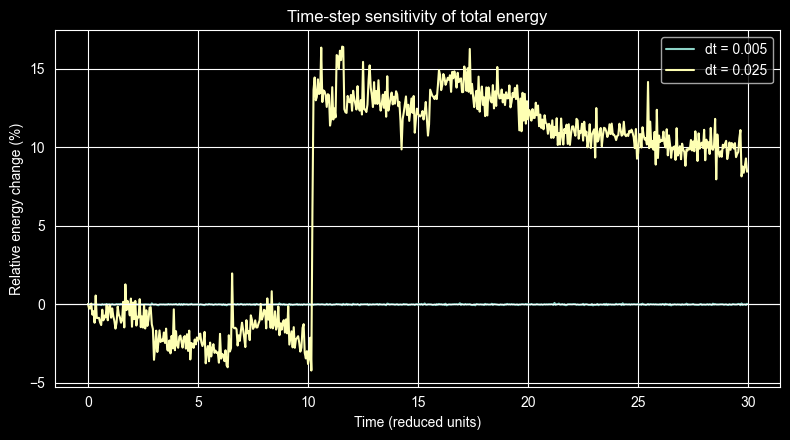

In [19]:
# 2_1
def relative_energy_change_percent(energy):
    # Return 100 * (E(t) - E(0)) / |E(0)|
    return 100 * (energy - energy[0]) / abs(energy[0])

# Calculate the two relative-energy-change arrays
energy_change_ref = relative_energy_change_percent(ref["energy"])
energy_change_large = relative_energy_change_percent(large["energy"])

plt.figure(figsize=(8, 4.5))

# Plot both curves against their corresponding time arrays
plt.plot(ref["time"], energy_change_ref, label="dt = 0.005")
plt.plot(large["time"], energy_change_large, label="dt = 0.025")

plt.axhline(0, linewidth=0.8)
plt.xlabel("Time (reduced units)")
plt.ylabel("Relative energy change (%)")
plt.title("Time-step sensitivity of total energy")
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
# 2-2
dt_ref = 0.005
dt_large = 0.025
final_ref = energy_change_ref[-1]
max_abs_ref = np.max(np.abs(energy_change_ref))

final_large = energy_change_large[-1]
max_abs_large = np.max(np.abs(energy_change_large))

print(f"Reference dt = {dt_ref:.3f}")
print(f"  Final relative energy change: {final_ref:.3f} %")
print(f"  Maximum |relative change|:    {max_abs_ref:.3f} %")

print(f"\nLarge dt = {dt_large:.3f}")
print(f"  Final relative energy change: {final_large:.3f} %")
print(f"  Maximum |relative change|:    {max_abs_large:.3f} %")

Reference dt = 0.005
  Final relative energy change: 0.014 %
  Maximum |relative change|:    0.084 %

Large dt = 0.025
  Final relative energy change: 8.432 %
  Maximum |relative change|:    16.406 %


### 2.3 Interpretation

a. Which run is numerically more trustworthy?

The smaller time step (\\(\Delta t = 0.005\\)) is more trustworthy because it generally produces smaller numerical errors and better total energy conservation.

b. Does the poor run necessarily look obviously “wrong” if you inspect only the particle coordinates?

No. The particle trajectories may still look physically reasonable, even when significant numerical errors are present. Therefore, visual inspection alone is insufficient to assess simulation accuracy.

c. Why is energy conservation a useful diagnostic for an NVE molecular-dynamics calculation?

In an NVE ensemble, total energy should remain constant because no energy is exchanged with the surroundings. Significant energy drift or fluctuations can indicate numerical integration errors, such as using an excessively large time step.

## Part 3– From atomic trajectories to the diffusion coefficient

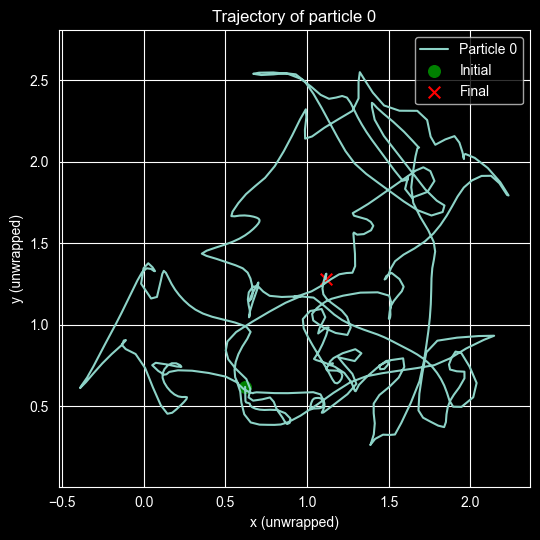

In [26]:
### 3.1 Follow one particle
trajectory_ref = ref["trajectory"]
particle_index = 0

# Extract the unwrapped trajectory of particle 0
particle_path = trajectory_ref[:, particle_index, :]

plt.figure(figsize=(5.5, 5.5))

# Plot x versus y for particle_path
plt.plot(particle_path[:, 0], particle_path[:, 1], label="Particle 0")

# Mark the initial and final positions
plt.scatter(particle_path[0, 0], particle_path[0, 1],
            color="green", marker="o", s=70, label="Initial")

plt.scatter(particle_path[-1, 0], particle_path[-1, 1],
            color="red", marker="x", s=70, label="Final")

plt.xlabel("x (unwrapped)")
plt.ylabel("y (unwrapped)")
plt.title("Trajectory of particle 0")
plt.axis("equal")
plt.legend()
plt.tight_layout()
plt.show()

The particle follows an irregular path due to interactions with surrounding particles, which continuously change its velocity and direction. This behavior is consistent with microscopic diffusion, where molecular motion produces random-looking trajectories and net displacement over time.

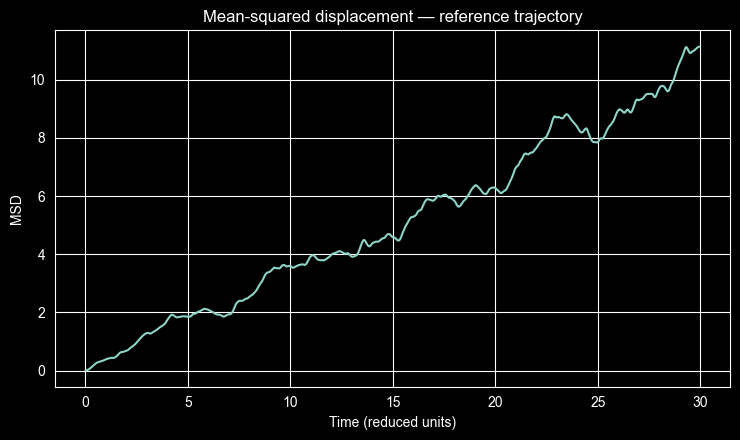

In [27]:
# 3.2 Mean-squared displacement
def mean_squared_displacement(trajectory):
    # trajectory shape: (n_frames, n_particles, 2)

    # TODO 1: displacement of every particle relative to its initial position
    displacement = trajectory - trajectory[0]

    # TODO 2: squared magnitude of each displacement vector
    squared_displacement = np.sum(displacement**2, axis=2)

    # TODO 3: average over particles at each time
    msd = np.mean(squared_displacement, axis=1)

    return msd

# Calculate the reference MSD
msd_ref = mean_squared_displacement(ref["trajectory"])

plt.figure(figsize=(7.5, 4.5))

# Plot reference MSD versus time
plt.plot(ref["time"], msd_ref, label="Reference MSD")

plt.xlabel("Time (reduced units)")
plt.ylabel("MSD")
plt.title("Mean-squared displacement — reference trajectory")
plt.tight_layout()
plt.show()

### Understanding the Three Calculations

The Mean Squared Displacement (MSD) equation is:

$$\mathrm{MSD}(t) = \frac{1}{N}\sum_{i=1}^{N}|\mathbf{r}_i(t) - \mathbf{r}_i(0)|^2$$

1. **Displacement:** `trajectory - trajectory[0]` subtracts each particle's initial position from its position at every time.
2. **Squared Displacement:** `np.sum(displacement**2, axis=2)` calculates $\Delta x_i^2 + \Delta y_i^2$ for each particle.
3. **Ensemble Average:** `np.mean(squared_displacement, axis=1)` averages over all 36 particles at each time point.

The result is one MSD value for each sampled time.

---

#### Short Answer for Your Notebook

Averaging over many particles reduces the influence of individual random fluctuations and provides a more statistically reliable measure of diffusion. A single particle's displacement may be highly irregular and is less representative of the overall transport behavior.

---

> **Important for the Next Section:**
> In two-dimensional normal diffusion, the long-time MSD approximately follows:
>
> $$\mathrm{MSD}(t) \approx 4Dt$$
>
> where $D$ is the diffusion coefficient. This relationship will allow you to estimate $D$ from the slope of the MSD curve.

Reference-run slope = 0.34423
Reference-run D     = 0.08606


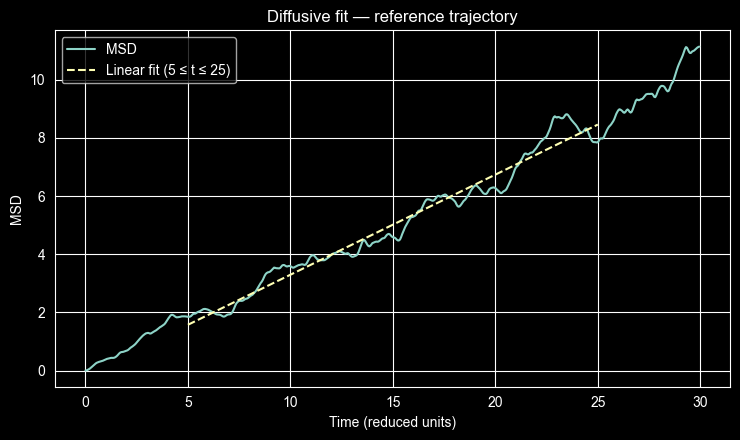

In [28]:
## 3.3 Obtain D
def fit_diffusion_coefficient(time, msd, fit_start=5.0, fit_end=25.0, dimensions=2):
    mask = (time >= fit_start) & (time <= fit_end)

    # TODO 1: linear fit MSD = slope * t + intercept
    slope, intercept = np.polyfit(time[mask], msd[mask], 1)

    # TODO 2: convert the slope to D using slope = 2 d D
    D = slope / (2 * dimensions)

    return D, slope, intercept, mask

# Fit the reference trajectory
D_ref, slope_ref, intercept_ref, fit_mask_ref = fit_diffusion_coefficient(
    ref["time"], msd_ref
)

print(f"Reference-run slope = {slope_ref:.5f}")
print(f"Reference-run D     = {D_ref:.5f}")

plt.figure(figsize=(7.5, 4.5))
plt.plot(ref["time"], msd_ref, label="MSD")

# Overlay the fitted straight line over the fitting interval
plt.plot(
    ref["time"][fit_mask_ref],
    slope_ref * ref["time"][fit_mask_ref] + intercept_ref,
    "--",
    label="Linear fit (5 ≤ t ≤ 25)"
)

plt.xlabel("Time (reduced units)")
plt.ylabel("MSD")
plt.title("Diffusive fit — reference trajectory")
plt.legend()
plt.tight_layout()
plt.show()

### Understanding the Mathematics

For normal diffusion in $d$ dimensions:

$$\mathrm{MSD}(t) = 2dDt + C$$

Since your simulation is two-dimensional ($d=2$):

$$\mathrm{MSD}(t) = 4Dt + C$$

Comparing this with a straight line equation ($y = mx + b$):

$$\boxed{D = \frac{\text{slope}}{4}}$$

---

### What does `np.polyfit(..., 1)` do?

It finds the best-fitting straight line through the MSD data between $t = 5$ and $t = 25$ using the method of least squares.

* **slope:** How quickly MSD increases with time ($m$).
* **intercept:** The fitted constant ($C$ or $b$).
* **$D$:** The estimated self-diffusion coefficient.

**Physical Interpretation:** A larger $D$ means particles spread more rapidly through the fluid.

---

> **Note on Fitting:**
> The relationship $\mathrm{MSD} \approx 4Dt + C$ applies specifically in the **diffusive regime**. The early-time motion may be ballistic (inertial), so fitting only over the specified interval ($t = 5$ to $t = 25$) avoids fitting the initial non-diffusive regime.

## 3.4 What if the time step is poor
Repeat only the MSD fit for the large-time-step trajectory and calculate the corresponding apparent
diffusion coefficient.

Compare the two values. The two estimates do not have to differ in any particular direction. The
important question is whether the large-time-step value should be trusted.

Answer:

Can a smooth-looking MSD curve or a plausible value of D compensate for poor numerical
energy conservation? Why or why not

Reference dt: D = 0.08606
Large dt:     D = 0.12007


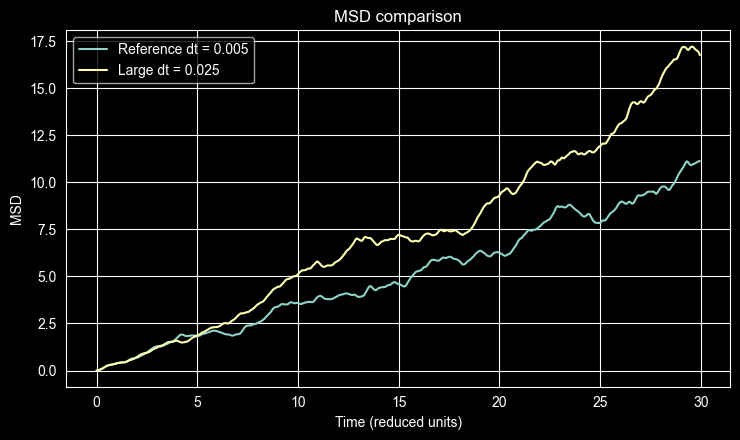

In [29]:
# TODO 1: calculate the large-time-step MSD
msd_large = mean_squared_displacement(large["trajectory"])

# TODO 2: fit the apparent diffusion coefficient
D_large, slope_large, intercept_large, fit_mask_large = fit_diffusion_coefficient(
    large["time"], msd_large
)

print(f"Reference dt: D = {D_ref:.5f}")
print(f"Large dt:     D = {D_large:.5f}")

plt.figure(figsize=(7.5, 4.5))

# Plot both MSD curves for comparison
plt.plot(ref["time"], msd_ref, label="Reference dt = 0.005")
plt.plot(large["time"], msd_large, label="Large dt = 0.025")

plt.xlabel("Time (reduced units)")
plt.ylabel("MSD")
plt.title("MSD comparison")
plt.legend()
plt.tight_layout()
plt.show()

Can a smooth-looking MSD curve or a plausible value of D compensate for poor numerical energy conservation? Why or why not?

No. A smooth MSD curve or a plausible diffusion coefficient does not guarantee numerical accuracy. Poor energy conservation indicates integration errors that may affect particle dynamics and transport properties, making the estimated diffusion coefficient unreliable.
Important physical interpretation
Remember the difference between these two measurements:
- Energy conservation: Evaluates the numerical reliability of the NVE simulation.
- MSD and diffusion coefficient: Describe how particles move and spread over time.
Even if both simulations produce similar diffusion coefficients, this does not establish that the large-time-step simulation is reliable.

Key takeaway: A physically plausible result does not necessarily mean the underlying MD simulation is numerically accurate.

### Part 4– Return to the continuum description

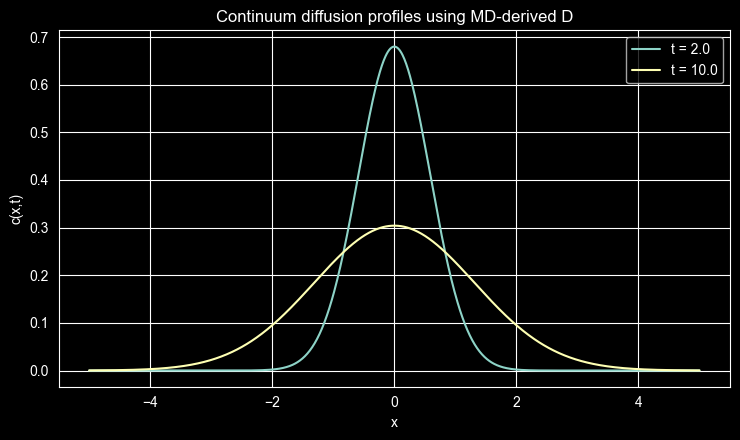

In [30]:
def gaussian_diffusion_profile(x, t, D):
    # TODO: implement the 1D continuum solution
    return (1 / np.sqrt(4 * np.pi * D * t)) * np.exp(-x**2 / (4 * D * t))

x = np.linspace(-5.0, 5.0, 1000)
times_to_plot = [2.0, 10.0]

plt.figure(figsize=(7.5, 4.5))
for t in times_to_plot:
    # Calculate and plot c(x,t) using D_ref
    c = gaussian_diffusion_profile(x, t, D_ref)
    plt.plot(x, c, label=f"t = {t}")

plt.xlabel("x")
plt.ylabel("c(x,t)")
plt.title("Continuum diffusion profiles using MD-derived D")
plt.legend()
plt.tight_layout()
plt.show()

### 2. Understanding the Equation

The one-dimensional continuum diffusion solution is:

$$\boxed{c(x,t) = \frac{1}{\sqrt{4\pi Dt}} \exp\left(-\frac{x^2}{4Dt}\right)}$$

This is a Gaussian distribution representing the spreading of an initially localized, normalized concentration profile.

* **$x$:** Position
* **$t$:** Time
* **$D$:** Diffusion coefficient obtained from your MD simulation
* **$c(x,t)$:** Normalized concentration profile

As time increases, the distribution spreads while its total integral remains equal to 1.

---

### 3. Written Answers for Your Notebook

**a. How does the concentration profile change with time?**
As time increases, the concentration profile becomes broader and its peak decreases, indicating that particles spread over a larger spatial region.

**b. What information from the atomistic simulation is retained in the continuum model through $D$?**
The diffusion coefficient $D$ retains information about the average rate of particle spreading obtained from the atomistic simulation, including the collective effects of molecular interactions on long-time mobility.

**c. What microscopic information is no longer visible once the system is represented only through $c(x,t)$ and $D$?**
Individual particle trajectories, velocities, interparticle forces, collisions, and detailed molecular interactions are no longer explicitly represented in the continuum model.

---

### 4. Key Connection Between MD and Continuum Modeling

| Molecular Dynamics (2D) | Continuum Model (1D) |
| :--- | :--- |
| Particle positions and trajectories | $c(x,t)$ predicts how a normalized profile spreads |
| Mean-Squared Displacement: $\mathrm{MSD}(t) \approx 4Dt + C$ | |
| Diffusion Coefficient: $D = \text{slope} / 4$ | |

> **Important Distinction:**
> Your MD simulation is two-dimensional, but the continuum equation provided is one-dimensional. This is valid here because $D$ describes diffusion along each Cartesian direction in an isotropic system, assuming normal diffusion.
>
> The continuum Gaussian describes an idealized spreading process, not the actual instantaneous particle-density profile inside your periodic MD simulation.

### Final Part

The Lennard–Jones potential \\(U(r)\\) describes interactions between particles, and the forces are calculated from its negative gradient, \\(F=-\nabla U\\). These forces are used in the Verlet integration method to generate particle trajectories, from which the mean-squared displacement (MSD) is calculated. The diffusion coefficient \\(D\\) is then obtained from the slope of the MSD versus time, connecting microscopic particle motion to macroscopic transport behavior. Finally, \\(D\\) is used in the continuum diffusion equation \\(c(x,t)\\) to describe how concentration spreads over time without explicitly tracking individual particles.